<a href="https://colab.research.google.com/github/ananyachikkur-cs/signal-and-system-lab/blob/main/lab4_txt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Linearity: True
Time Invariant: True
Causal: Yes
Memoryless: No (System has memory)
BIBO Stable: True
Invertible: True


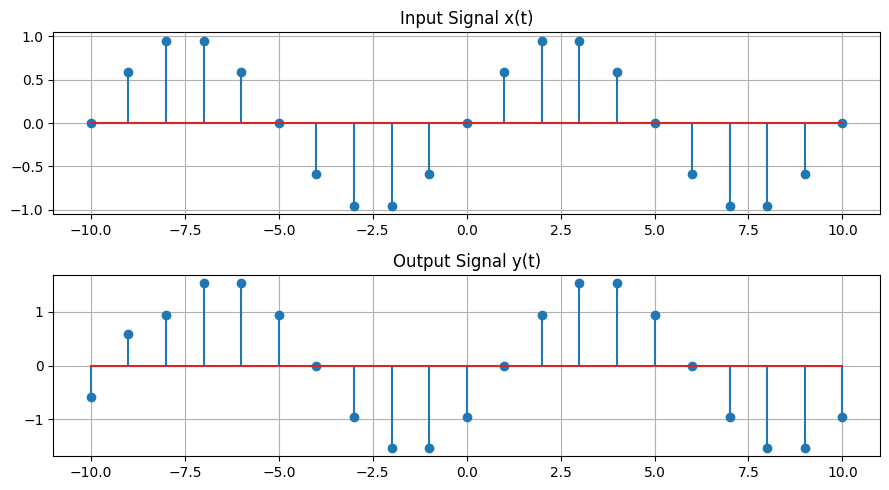

In [21]:

import numpy as np
import matplotlib.pyplot as plt

# Time axis
t = np.arange(-10, 11, 1)

# Input signal
x = np.sin(0.2 * np.pi * t)

# System equation
def system(x):
    return x + np.roll(x, 2)


# 1. LINEARITY TEST

x1 = np.sin(0.2 * np.pi * t)
x2 = np.cos(0.2 * np.pi * t)

a = 2
b = 3

LHS = system(a*x1 + b*x2)
RHS = a*system(x1) + b*system(x2)

print("Linearity:", np.allclose(LHS, RHS))


# 2. TIME INVARIANCE TEST

shift = 3

y1 = system(np.roll(x, shift))
y2 = np.roll(system(x), shift)

print("Time Invariant:", np.allclose(y1, y2))


# 3. CAUSALITY

# System uses present and past input
print("Causal: Yes")


# 4. MEMORY

# System uses x(t-2)
print("Memoryless: No (System has memory)")


# 5. BIBO STABILITY

bounded_input = np.ones(len(t))
output = system(bounded_input)

print("BIBO Stable:", np.max(np.abs(output)) < np.inf)


# 6. INVERTIBILITY

# Check whether different inputs can produce the same output
test1 = np.ones(len(t))
test2 = -np.ones(len(t))

print("Invertible:", not np.allclose(system(test1),
                                    system(test2)))


# Plot input and output

plt.figure(figsize=(9, 5))

plt.subplot(2, 1, 1)
plt.stem(t, x)
plt.title("Input Signal x(t)")
plt.grid()

plt.subplot(2, 1, 2)
plt.stem(t, system(x))
plt.title("Output Signal y(t)")
plt.grid()

plt.tight_layout()
plt.show()
